# busch2018

Generated by GreenSloth from this model's validations.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from mxlpy import scan

In [2]:
import math

import numpy as np
import sympy.physics.units as su

from mxlpy import Slider, SteadyStateModelBuilder

def _derived_Phi(C, O, S_co):
    return (1000 * O) / (S_co * C)

def _derived_Gamma_star(O, S_co):
    return (500 * O) / (S_co)

def _derived_beta(alpha_G_max, alpha_S_max):
    return (3 * alpha_G_max) / (max(3 * alpha_G_max + 2 * alpha_S_max, 1e-12))

def _derived_Wc(C, O, Vcmax, Kc, Ko):
    return (Vcmax * C) / (C + Kc * (1 + (O) / (Ko)))

def _derived_Vo_c(Phi, Wc):
    return Wc * Phi

def _derived_alpha_G_c(alpha_G_max, N_max, beta, Vo_c):
    return min(alpha_G_max, (N_max * beta) / (Vo_c))

def _derived_alpha_S_c(alpha_S_max, N_max, beta, Vo_c):
    return min(alpha_S_max, (3 * N_max * ((1) - (beta))) / (2 * Vo_c))

def _derived_alpha_G_j(J, alpha_G_max, N_max, Phi, beta):
    return (min(alpha_G_max, (4 * N_max * beta * ((1) / (Phi) + 1)) / ((J) - (N_max * (2 * beta + 6)))) if (J) - (N_max * (2 * beta + 6)) > 0 else alpha_G_max)

def _derived_alpha_S_j(J, alpha_S_max, N_max, Phi, beta):
    return (min(alpha_S_max, (6 * N_max * ((1) - (beta)) * ((1) / (Phi) + 1)) / ((J) - (N_max * (2 * beta + 6)))) if (J) - (N_max * (2 * beta + 6)) > 0 else alpha_S_max)

def _derived_Wj(J, Phi, alpha_G_j, alpha_S_j):
    return (J) / (4 + (4 + 8 * alpha_G_j + 4 * alpha_S_j) * Phi)

def _derived_Vo_j(Phi, Wj):
    return Wj * Phi

def _derived_alpha_G_p(Tp, alpha_G_max, N_max, Phi, beta):
    return min(alpha_G_max, beta * (N_max * (((2) / (Phi)) - (1))) / (6 * Tp + 3 * N_max * ((2) - (beta))))

def _derived_alpha_S_p(Tp, alpha_S_max, N_max, Phi, beta):
    return min(alpha_S_max, 1.5 * ((1) - (beta)) * (N_max * (((2) / (Phi)) - (1))) / (6 * Tp + 3 * N_max * ((2) - (beta))))

def _derived_Wp(Tp, Phi, alpha_G_p, alpha_S_p):
    return (3 * Tp) / (max((1) - (0.5 * (1 + 3 * alpha_G_p + 4 * alpha_S_p) * Phi), 1e-12))

def _derived_Vo_p(Phi, Wp):
    return Wp * Phi

def _derived_Gamma_star_c(O, S_co, alpha_G_c):
    return (500 * ((1) - (alpha_G_c)) * O) / (S_co)

def _derived_Ac(C, Rd, Wc, Gamma_star_c):
    return (Wc * ((1) - ((Gamma_star_c) / (C)))) - (Rd)

def _derived_Gamma_star_j(O, S_co, alpha_G_j):
    return (500 * ((1) - (alpha_G_j)) * O) / (S_co)

def _derived_Aj(C, Rd, Wj, Gamma_star_j):
    return (Wj * ((1) - ((Gamma_star_j) / (C)))) - (Rd)

def _derived_Gamma_star_p(O, S_co, alpha_G_p):
    return (500 * ((1) - (alpha_G_p)) * O) / (S_co)

def _derived_Ap(C, Rd, Wp, Gamma_star_p):
    return (Wp * ((1) - ((Gamma_star_p) / (C)))) - (Rd)

def _derived_A(Ac, Aj, Ap):
    return min(Ac, Aj, Ap)

def _derived_alpha_G(alpha_G_c, alpha_G_j, alpha_G_p, Ac, Aj, A):
    return (alpha_G_c if Ac <= A else alpha_G_j if Aj <= A else alpha_G_p)

def _derived_alpha_S(alpha_S_c, alpha_S_j, alpha_S_p, Ac, Aj, A):
    return (alpha_S_c if Ac <= A else alpha_S_j if Aj <= A else alpha_S_p)

def _derived_alpha_total(alpha_G, alpha_S):
    return alpha_G + alpha_S

def _derived_Vo(Vo_c, Vo_j, Vo_p, Ac, Aj, A):
    return (Vo_c if Ac <= A else Vo_j if Aj <= A else Vo_p)

def _derived_N_G(alpha_G, Vo):
    return alpha_G * Vo

def _derived_N_S(alpha_S, Vo):
    return (2) / (3) * alpha_S * Vo

def _derived_N_total(N_G, N_S):
    return N_G + N_S

def _derived_Ja(Phi, alpha_G, alpha_S, Vo):
    return (4 + (4 + 8 * alpha_G + 4 * alpha_S) * Phi) * (Vo) / (Phi)

def get_model() -> SteadyStateModelBuilder:
    m = SteadyStateModelBuilder()
    m.add_parameter("C", 40, unit=su.pascal, display_name="C", tex_name="C", slider=Slider(min="5", max="200", step="1"))
    m.add_parameter("O", 19.7, unit=su.pascal*su.kilo, display_name="O", tex_name="O", slider=Slider(min="0.2", max="40", step="0.2"))
    m.add_parameter("Vcmax", 103.9, unit=su.mol*su.micro/(su.meter**2*su.second), display_name="Vcmax", tex_name="V_{c,max}", slider=Slider(min="20", max="200", step="0.5"))
    m.add_parameter("J", 185.2, unit=su.mol*su.micro/(su.meter**2*su.second), display_name="J", tex_name="J", slider=Slider(min="10", max="400", step="1"))
    m.add_parameter("Tp", 11.5, unit=su.mol*su.micro/(su.meter**2*su.second), display_name="Tp", tex_name="T_p", slider=Slider(min="2", max="25", step="0.1"))
    m.add_parameter("Rd", 1.29, unit=su.mol*su.micro/(su.meter**2*su.second), display_name="Rd", tex_name="R_d", slider=Slider(min="0", max="5", step="0.05"))
    m.add_parameter("alpha_G_max", 0.09, unit=None, display_name="alpha_G_max", tex_name="\\alpha_G^{max}", slider=Slider(min="0", max="1", step="0.01"))
    m.add_parameter("alpha_S_max", 0.38, unit=None, display_name="alpha_S_max", tex_name="\\alpha_S^{max}", slider=Slider(min="0", max="0.75", step="0.01"))
    m.add_parameter("N_max", 1.21, unit=su.mol*su.micro/(su.meter**2*su.second), display_name="N_max", tex_name="N^{max}", slider=Slider(min="0", max="5", step="0.01"))
    m.add_parameter("Kc", 27.238, unit=su.pascal, display_name="Kc", tex_name="K_c")
    m.add_parameter("Ko", 16.582, unit=su.pascal*su.kilo, display_name="Ko", tex_name="K_o")
    m.add_parameter("S_co", 2805.236441357201, unit=None, display_name="S_co", tex_name="S_{c/o}")
    m.add_derived("Phi", _derived_Phi, args=["C", "O", "S_co"], unit=None, display_name="Phi", tex_name="\\Phi")
    m.add_derived("Gamma_star", _derived_Gamma_star, args=["O", "S_co"], unit=su.pascal, display_name="Gamma_star", tex_name="\\Gamma^*")
    m.add_derived("beta", _derived_beta, args=["alpha_G_max", "alpha_S_max"], unit=None, display_name="beta", tex_name="\\beta")
    m.add_derived("Wc", _derived_Wc, args=["C", "O", "Vcmax", "Kc", "Ko"], unit=su.mol*su.micro/(su.meter**2*su.second), display_name="Wc", tex_name="W_c")
    m.add_derived("Vo_c", _derived_Vo_c, args=["Phi", "Wc"], unit=su.mol*su.micro/(su.meter**2*su.second), display_name="Vo_c", tex_name="V_o^c")
    m.add_derived("alpha_G_c", _derived_alpha_G_c, args=["alpha_G_max", "N_max", "beta", "Vo_c"], unit=None, display_name="alpha_G_c", tex_name="\\alpha_G^c")
    m.add_derived("alpha_S_c", _derived_alpha_S_c, args=["alpha_S_max", "N_max", "beta", "Vo_c"], unit=None, display_name="alpha_S_c", tex_name="\\alpha_S^c")
    m.add_derived("alpha_G_j", _derived_alpha_G_j, args=["J", "alpha_G_max", "N_max", "Phi", "beta"], unit=None, display_name="alpha_G_j", tex_name="\\alpha_G^j")
    m.add_derived("alpha_S_j", _derived_alpha_S_j, args=["J", "alpha_S_max", "N_max", "Phi", "beta"], unit=None, display_name="alpha_S_j", tex_name="\\alpha_S^j")
    m.add_derived("Wj", _derived_Wj, args=["J", "Phi", "alpha_G_j", "alpha_S_j"], unit=su.mol*su.micro/(su.meter**2*su.second), display_name="Wj", tex_name="W_j")
    m.add_derived("Vo_j", _derived_Vo_j, args=["Phi", "Wj"], unit=su.mol*su.micro/(su.meter**2*su.second), display_name="Vo_j", tex_name="V_o^j")
    m.add_derived("alpha_G_p", _derived_alpha_G_p, args=["Tp", "alpha_G_max", "N_max", "Phi", "beta"], unit=None, display_name="alpha_G_p", tex_name="\\alpha_G^p")
    m.add_derived("alpha_S_p", _derived_alpha_S_p, args=["Tp", "alpha_S_max", "N_max", "Phi", "beta"], unit=None, display_name="alpha_S_p", tex_name="\\alpha_S^p")
    m.add_derived("Wp", _derived_Wp, args=["Tp", "Phi", "alpha_G_p", "alpha_S_p"], unit=su.mol*su.micro/(su.meter**2*su.second), display_name="Wp", tex_name="W_p")
    m.add_derived("Vo_p", _derived_Vo_p, args=["Phi", "Wp"], unit=su.mol*su.micro/(su.meter**2*su.second), display_name="Vo_p", tex_name="V_o^p")
    m.add_derived("Gamma_star_c", _derived_Gamma_star_c, args=["O", "S_co", "alpha_G_c"], unit=su.pascal, display_name="Gamma_star_c", tex_name="\\Gamma^*_{\\alpha_G,c}")
    m.add_derived("Ac", _derived_Ac, args=["C", "Rd", "Wc", "Gamma_star_c"], unit=su.mol*su.micro/(su.meter**2*su.second), display_name="Ac", tex_name="A_c")
    m.add_derived("Gamma_star_j", _derived_Gamma_star_j, args=["O", "S_co", "alpha_G_j"], unit=su.pascal, display_name="Gamma_star_j", tex_name="\\Gamma^*_{\\alpha_G,j}")
    m.add_derived("Aj", _derived_Aj, args=["C", "Rd", "Wj", "Gamma_star_j"], unit=su.mol*su.micro/(su.meter**2*su.second), display_name="Aj", tex_name="A_j")
    m.add_derived("Gamma_star_p", _derived_Gamma_star_p, args=["O", "S_co", "alpha_G_p"], unit=su.pascal, display_name="Gamma_star_p", tex_name="\\Gamma^*_{\\alpha_G,p}")
    m.add_derived("Ap", _derived_Ap, args=["C", "Rd", "Wp", "Gamma_star_p"], unit=su.mol*su.micro/(su.meter**2*su.second), display_name="Ap", tex_name="A_p")
    m.add_derived("A", _derived_A, args=["Ac", "Aj", "Ap"], unit=su.mol*su.micro/(su.meter**2*su.second), display_name="A", tex_name="A")
    m.add_derived("alpha_G", _derived_alpha_G, args=["alpha_G_c", "alpha_G_j", "alpha_G_p", "Ac", "Aj", "A"], unit=None, display_name="alpha_G", tex_name="\\alpha_G")
    m.add_derived("alpha_S", _derived_alpha_S, args=["alpha_S_c", "alpha_S_j", "alpha_S_p", "Ac", "Aj", "A"], unit=None, display_name="alpha_S", tex_name="\\alpha_S")
    m.add_derived("alpha_total", _derived_alpha_total, args=["alpha_G", "alpha_S"], unit=None, display_name="alpha_total", tex_name="\\alpha_{total}")
    m.add_derived("Vo", _derived_Vo, args=["Vo_c", "Vo_j", "Vo_p", "Ac", "Aj", "A"], unit=su.mol*su.micro/(su.meter**2*su.second), display_name="Vo", tex_name="V_o")
    m.add_derived("N_G", _derived_N_G, args=["alpha_G", "Vo"], unit=su.mol*su.micro/(su.meter**2*su.second), display_name="N_G", tex_name="N_G")
    m.add_derived("N_S", _derived_N_S, args=["alpha_S", "Vo"], unit=su.mol*su.micro/(su.meter**2*su.second), display_name="N_S", tex_name="N_S")
    m.add_derived("N_total", _derived_N_total, args=["N_G", "N_S"], unit=su.mol*su.micro/(su.meter**2*su.second), display_name="N_total", tex_name="N_{total}")
    m.add_derived("Ja", _derived_Ja, args=["Phi", "alpha_G", "alpha_S", "Vo"], unit=su.mol*su.micro/(su.meter**2*su.second), display_name="Ja", tex_name="J_a")
    return m


## Figure 3: A–Ci fit and photorespiratory N assimilation (sunflower)

In [3]:
tables = {}

# Scan fit
to_scan = pd.DataFrame({"C": np.linspace(5, 200, 196), "O": 19.7, "Vcmax": 103.9, "J": 185.2, "Tp": 11.5, "Rd": 1.29, "alpha_G_max": 0.09, "alpha_S_max": 0.38, "N_max": 1.21})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["Ac","Aj","Ap","A","alpha_G","alpha_S","alpha_total","N_G","N_S","N_total"]].isna().any(axis=None)
tables["fit"] = {
    "x": np.linspace(5, 200, 196),
    "Ac": frame["Ac"].to_numpy(),
    "Aj": frame["Aj"].to_numpy(),
    "Ap": frame["Ap"].to_numpy(),
    "A": frame["A"].to_numpy(),
    "alpha_G": frame["alpha_G"].to_numpy(),
    "alpha_S": frame["alpha_S"].to_numpy(),
    "alpha_total": frame["alpha_total"].to_numpy(),
    "N_G": frame["N_G"].to_numpy(),
    "N_S": frame["N_S"].to_numpy(),
    "N_total": frame["N_total"].to_numpy(),
}

  0%|          | 0/196 [00:00<?, ?it/s]

100%|██████████| 196/196 [00:00<00:00, 3529.45it/s]

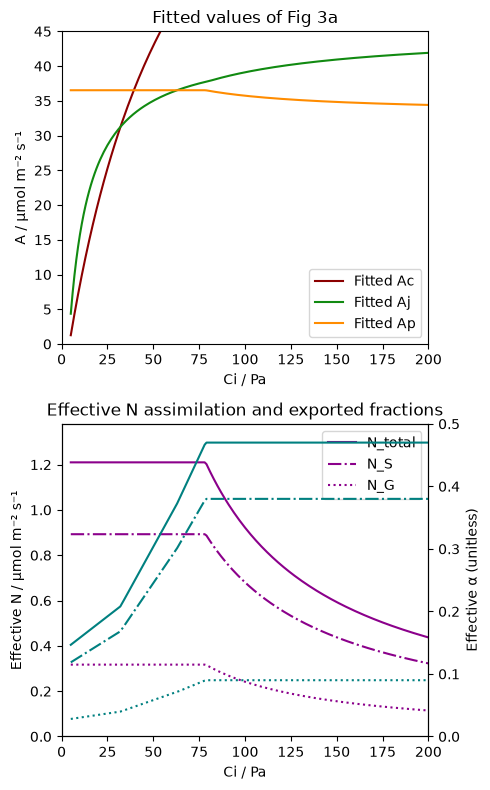

In [4]:
fig, axs = plt.subplots(nrows=2, ncols=1, figsize=(5, 8), squeeze=False)
ax0 = axs[0, 0]
ax0.set_title("Fitted values of Fig 3a")
ax0.plot(tables["fit"]["x"], tables["fit"]["Ac"], color="#8b0000", label="Fitted Ac")
ax0.plot(tables["fit"]["x"], tables["fit"]["Aj"], color="#118a11", label="Fitted Aj")
ax0.plot(tables["fit"]["x"], tables["fit"]["Ap"], color="#ff8c00", label="Fitted Ap")
ax0.set_xlabel("Ci / Pa")
ax0.set_ylabel("A / µmol m⁻² s⁻¹")
ax0.set_xlim(0, 200)
ax0.set_ylim(0, 45)
ax0.legend()
ax1 = axs[1, 0]
ax1.set_title("Effective N assimilation and exported fractions")
ax1_right = ax1.twinx()
ax1.plot(tables["fit"]["x"], tables["fit"]["N_total"], color="#8b008b", label="N_total")
ax1.plot(tables["fit"]["x"], tables["fit"]["N_S"], color="#8b008b", ls="-.", label="N_S")
ax1.plot(tables["fit"]["x"], tables["fit"]["N_G"], color="#8b008b", ls=":", label="N_G")
ax1_right.plot(tables["fit"]["x"], tables["fit"]["alpha_total"], color="#008080", label="α_total")
ax1_right.plot(tables["fit"]["x"], tables["fit"]["alpha_S"], color="#008080", ls="-.", label="α_S")
ax1_right.plot(tables["fit"]["x"], tables["fit"]["alpha_G"], color="#008080", ls=":", label="α_G")
ax1.set_xlabel("Ci / Pa")
ax1.set_ylabel("Effective N / µmol m⁻² s⁻¹")
ax1.set_xlim(0, 200)
ax1.set_ylim(0, 1.38)
ax1_right.set_ylabel("Effective α (unitless)")
ax1_right.set_ylim(0, 0.5)
ax1.legend()
plt.tight_layout()
plt.show()

## Figure 3c: CO₂ response at ambient and minimal O₂

In [5]:
tables = {}

# Scan ambient
to_scan = pd.DataFrame({"C": np.linspace(5, 200, 196), "J": 168.7, "Tp": 10.2, "Rd": 1.29, "alpha_G_max": 0.09, "alpha_S_max": 0.38, "N_max": 1.21, "O": 19.7, "Vcmax": 92.4})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A"]].isna().any(axis=None)
tables["ambient"] = {
    "x": np.linspace(5, 200, 196),
    "A": frame["A"].to_numpy(),
}

# Scan minimal
to_scan = pd.DataFrame({"C": np.linspace(1, 200, 200), "J": 168.7, "Tp": 10.2, "Rd": 1.29, "alpha_G_max": 0.09, "alpha_S_max": 0.38, "N_max": 1.21, "O": 0.19, "Vcmax": 62.4})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A"]].isna().any(axis=None)
tables["minimal"] = {
    "x": np.linspace(1, 200, 200),
    "A": frame["A"].to_numpy(),
}

  0%|          | 0/196 [00:00<?, ?it/s]

100%|██████████| 196/196 [00:00<00:00, 3543.71it/s]

  0%|          | 0/200 [00:00<?, ?it/s]

100%|██████████| 200/200 [00:00<00:00, 3527.19it/s]

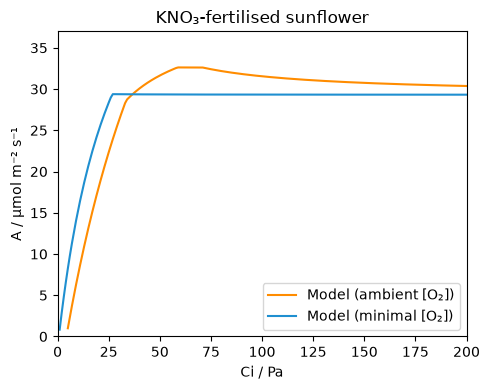

In [6]:
fig, axs = plt.subplots(nrows=1, ncols=1, figsize=(5, 4), squeeze=False)
ax0 = axs[0, 0]
ax0.set_title("KNO₃-fertilised sunflower")
ax0.plot(tables["ambient"]["x"], tables["ambient"]["A"], color="#ff8c00", label="Model (ambient [O₂])")
ax0.plot(tables["minimal"]["x"], tables["minimal"]["A"], color="#1f8fd0", label="Model (minimal [O₂])")
ax0.set_xlabel("Ci / Pa")
ax0.set_ylabel("A / µmol m⁻² s⁻¹")
ax0.set_xlim(0, 200)
ax0.set_ylim(0, 37)
ax0.legend()
plt.tight_layout()
plt.show()

## Figure 4: CO₂ response with amino acid export as glycine and serine

In [7]:
tables = {}

# Scan sat_none
to_scan = pd.DataFrame({"C": np.linspace(5, 150, 291), "O": 21, "Vcmax": 100, "Tp": 11.5, "Rd": 1, "N_max": 1.5, "alpha_G_max": 0, "alpha_S_max": 0, "J": 1000})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["Ac","Aj","Ap","A"]].isna().any(axis=None)
tables["sat_none"] = {
    "x": np.linspace(5, 150, 291),
    "Ac": frame["Ac"].to_numpy(),
    "Aj": frame["Aj"].to_numpy(),
    "Ap": frame["Ap"].to_numpy(),
    "A": frame["A"].to_numpy(),
}

# Scan sat_gly
to_scan = pd.DataFrame({"C": np.linspace(5, 150, 291), "O": 21, "Vcmax": 100, "Tp": 11.5, "Rd": 1, "N_max": 1.5, "alpha_G_max": 0.5, "alpha_S_max": 0, "J": 1000})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["Ac","Aj","Ap","A"]].isna().any(axis=None)
tables["sat_gly"] = {
    "x": np.linspace(5, 150, 291),
    "Ac": frame["Ac"].to_numpy(),
    "Aj": frame["Aj"].to_numpy(),
    "Ap": frame["Ap"].to_numpy(),
    "A": frame["A"].to_numpy(),
}

# Scan sat_ser
to_scan = pd.DataFrame({"C": np.linspace(5, 150, 291), "O": 21, "Vcmax": 100, "Tp": 11.5, "Rd": 1, "N_max": 1.5, "alpha_G_max": 0, "alpha_S_max": 0.4, "J": 1000})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["Ac","Aj","Ap","A"]].isna().any(axis=None)
tables["sat_ser"] = {
    "x": np.linspace(5, 150, 291),
    "Ac": frame["Ac"].to_numpy(),
    "Aj": frame["Aj"].to_numpy(),
    "Ap": frame["Ap"].to_numpy(),
    "A": frame["A"].to_numpy(),
}

# Scan sat_mix
to_scan = pd.DataFrame({"C": np.linspace(5, 150, 291), "O": 21, "Vcmax": 100, "Tp": 11.5, "Rd": 1, "N_max": 1.5, "alpha_G_max": 0.1, "alpha_S_max": 0.35, "J": 1000})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["Ac","Aj","Ap","A"]].isna().any(axis=None)
tables["sat_mix"] = {
    "x": np.linspace(5, 150, 291),
    "Ac": frame["Ac"].to_numpy(),
    "Aj": frame["Aj"].to_numpy(),
    "Ap": frame["Ap"].to_numpy(),
    "A": frame["A"].to_numpy(),
}

# Scan lim_none
to_scan = pd.DataFrame({"C": np.linspace(5, 150, 291), "O": 21, "Vcmax": 100, "Tp": 11.5, "Rd": 1, "N_max": 1.5, "alpha_G_max": 0, "alpha_S_max": 0, "J": 65})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["Ac","Aj","Ap","A"]].isna().any(axis=None)
tables["lim_none"] = {
    "x": np.linspace(5, 150, 291),
    "Ac": frame["Ac"].to_numpy(),
    "Aj": frame["Aj"].to_numpy(),
    "Ap": frame["Ap"].to_numpy(),
    "A": frame["A"].to_numpy(),
}

# Scan lim_gly
to_scan = pd.DataFrame({"C": np.linspace(5, 150, 291), "O": 21, "Vcmax": 100, "Tp": 11.5, "Rd": 1, "N_max": 1.5, "alpha_G_max": 0.5, "alpha_S_max": 0, "J": 65})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["Ac","Aj","Ap","A"]].isna().any(axis=None)
tables["lim_gly"] = {
    "x": np.linspace(5, 150, 291),
    "Ac": frame["Ac"].to_numpy(),
    "Aj": frame["Aj"].to_numpy(),
    "Ap": frame["Ap"].to_numpy(),
    "A": frame["A"].to_numpy(),
}

# Scan lim_ser
to_scan = pd.DataFrame({"C": np.linspace(5, 150, 291), "O": 21, "Vcmax": 100, "Tp": 11.5, "Rd": 1, "N_max": 1.5, "alpha_G_max": 0, "alpha_S_max": 0.4, "J": 65})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["Ac","Aj","Ap","A"]].isna().any(axis=None)
tables["lim_ser"] = {
    "x": np.linspace(5, 150, 291),
    "Ac": frame["Ac"].to_numpy(),
    "Aj": frame["Aj"].to_numpy(),
    "Ap": frame["Ap"].to_numpy(),
    "A": frame["A"].to_numpy(),
}

# Scan lim_mix
to_scan = pd.DataFrame({"C": np.linspace(5, 150, 291), "O": 21, "Vcmax": 100, "Tp": 11.5, "Rd": 1, "N_max": 1.5, "alpha_G_max": 0.1, "alpha_S_max": 0.35, "J": 65})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["Ac","Aj","Ap","A"]].isna().any(axis=None)
tables["lim_mix"] = {
    "x": np.linspace(5, 150, 291),
    "Ac": frame["Ac"].to_numpy(),
    "Aj": frame["Aj"].to_numpy(),
    "Ap": frame["Ap"].to_numpy(),
    "A": frame["A"].to_numpy(),
}

  0%|          | 0/291 [00:00<?, ?it/s]

 48%|████▊     | 140/291 [00:00<00:00, 1260.03it/s]

100%|██████████| 291/291 [00:00<00:00, 1869.68it/s]

  0%|          | 0/291 [00:00<?, ?it/s]

100%|██████████| 291/291 [00:00<00:00, 3445.86it/s]

  0%|          | 0/291 [00:00<?, ?it/s]

... (7 outputs left out)

  0%|          | 0/291 [00:00<?, ?it/s]

100%|██████████| 291/291 [00:00<00:00, 3587.76it/s]

  0%|          | 0/291 [00:00<?, ?it/s]

100%|██████████| 291/291 [00:00<00:00, 3505.14it/s]

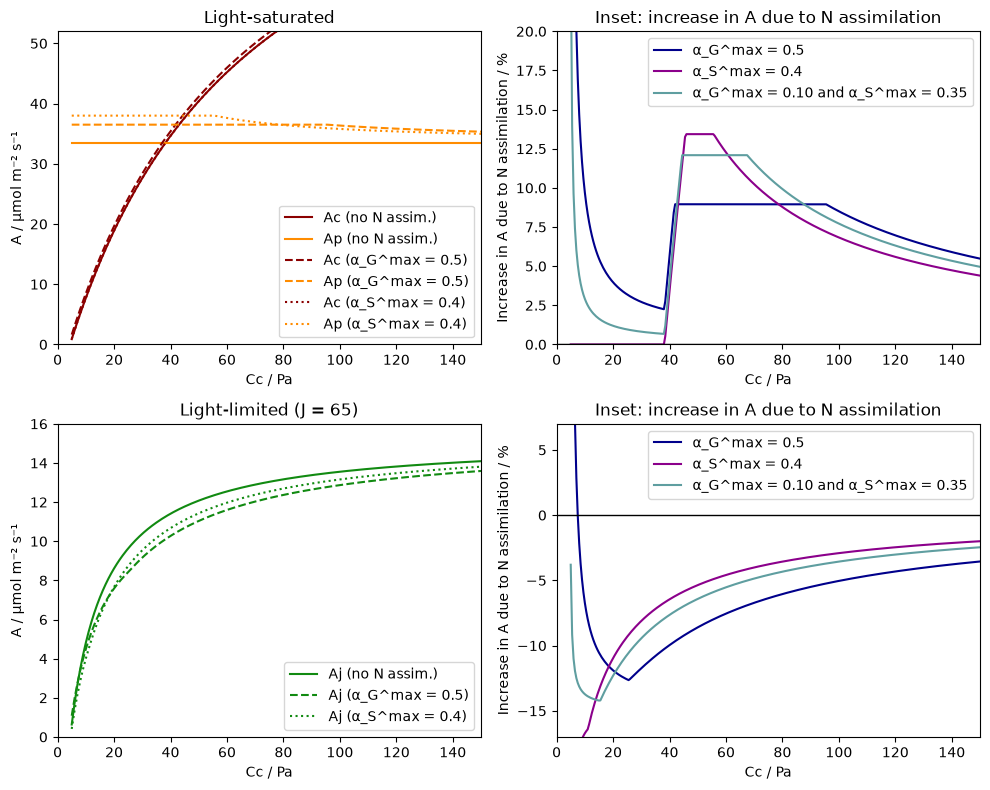

In [8]:
fig, axs = plt.subplots(nrows=2, ncols=2, figsize=(10, 8), squeeze=False)
ax0 = axs[0, 0]
ax0.set_title("Light-saturated")
ax0.plot(tables["sat_none"]["x"], tables["sat_none"]["Ac"], color="#8b0000", ls="-", label="Ac (no N assim.)")
ax0.plot(tables["sat_none"]["x"], tables["sat_none"]["Ap"], color="#ff8c00", ls="-", label="Ap (no N assim.)")
ax0.plot(tables["sat_none"]["x"], tables["sat_gly"]["Ac"], color="#8b0000", ls="--", label="Ac (α_G^max = 0.5)")
ax0.plot(tables["sat_none"]["x"], tables["sat_gly"]["Ap"], color="#ff8c00", ls="--", label="Ap (α_G^max = 0.5)")
ax0.plot(tables["sat_none"]["x"], tables["sat_ser"]["Ac"], color="#8b0000", ls=":", label="Ac (α_S^max = 0.4)")
ax0.plot(tables["sat_none"]["x"], tables["sat_ser"]["Ap"], color="#ff8c00", ls=":", label="Ap (α_S^max = 0.4)")
ax0.set_xlabel("Cc / Pa")
ax0.set_ylabel("A / µmol m⁻² s⁻¹")
ax0.set_xlim(0, 150)
ax0.set_ylim(0, 52)
ax0.legend()
ax1 = axs[0, 1]
ax1.set_title("Inset: increase in A due to N assimilation")
ax1.plot(tables["sat_none"]["x"], 100 * (((tables["sat_gly"]["A"]) / (tables["sat_none"]["A"])) - (1)), color="#00008b", label="α_G^max = 0.5")
ax1.plot(tables["sat_none"]["x"], 100 * (((tables["sat_ser"]["A"]) / (tables["sat_none"]["A"])) - (1)), color="#8b008b", label="α_S^max = 0.4")
ax1.plot(tables["sat_none"]["x"], 100 * (((tables["sat_mix"]["A"]) / (tables["sat_none"]["A"])) - (1)), color="#5f9ea0", label="α_G^max = 0.10 and α_S^max = 0.35")
ax1.set_xlabel("Cc / Pa")
ax1.set_ylabel("Increase in A due to N assimilation / %")
ax1.set_xlim(0, 150)
ax1.set_ylim(0, 20)
ax1.axhline(0, color="black", lw=1)
ax1.legend()
ax2 = axs[1, 0]
ax2.set_title("Light-limited (J = 65)")
ax2.plot(tables["lim_none"]["x"], tables["lim_none"]["Aj"], color="#118a11", ls="-", label="Aj (no N assim.)")
ax2.plot(tables["lim_none"]["x"], tables["lim_gly"]["Aj"], color="#118a11", ls="--", label="Aj (α_G^max = 0.5)")
ax2.plot(tables["lim_none"]["x"], tables["lim_ser"]["Aj"], color="#118a11", ls=":", label="Aj (α_S^max = 0.4)")
ax2.set_xlabel("Cc / Pa")
ax2.set_ylabel("A / µmol m⁻² s⁻¹")
ax2.set_xlim(0, 150)
ax2.set_ylim(0, 16)
ax2.legend()
ax3 = axs[1, 1]
ax3.set_title("Inset: increase in A due to N assimilation")
ax3.plot(tables["lim_none"]["x"], 100 * (((tables["lim_gly"]["A"]) / (tables["lim_none"]["A"])) - (1)), color="#00008b", label="α_G^max = 0.5")
ax3.plot(tables["lim_none"]["x"], 100 * (((tables["lim_ser"]["A"]) / (tables["lim_none"]["A"])) - (1)), color="#8b008b", label="α_S^max = 0.4")
ax3.plot(tables["lim_none"]["x"], 100 * (((tables["lim_mix"]["A"]) / (tables["lim_none"]["A"])) - (1)), color="#5f9ea0", label="α_G^max = 0.10 and α_S^max = 0.35")
ax3.set_xlabel("Cc / Pa")
ax3.set_ylabel("Increase in A due to N assimilation / %")
ax3.set_xlim(0, 150)
ax3.set_ylim(-17, 7)
ax3.axhline(0, color="black", lw=1)
ax3.legend()
plt.tight_layout()
plt.show()

## Supplementary Figure S4: modelled rates of RuBP oxygenation

In [9]:
tables = {}

# Scan vo
to_scan = pd.DataFrame({"C": np.linspace(4, 200, 197), "O": 19.7, "Vcmax": 103.9, "J": 185.2, "Tp": 11.5, "Rd": 1.29, "alpha_G_max": 0.09, "alpha_S_max": 0.38, "N_max": 1.21})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["Vo_c","Vo_j","Vo_p","Vo"]].isna().any(axis=None)
tables["vo"] = {
    "x": np.linspace(4, 200, 197),
    "Vo_c": frame["Vo_c"].to_numpy(),
    "Vo_j": frame["Vo_j"].to_numpy(),
    "Vo_p": frame["Vo_p"].to_numpy(),
    "Vo": frame["Vo"].to_numpy(),
}

  0%|          | 0/197 [00:00<?, ?it/s]

100%|██████████| 197/197 [00:00<00:00, 3540.98it/s]

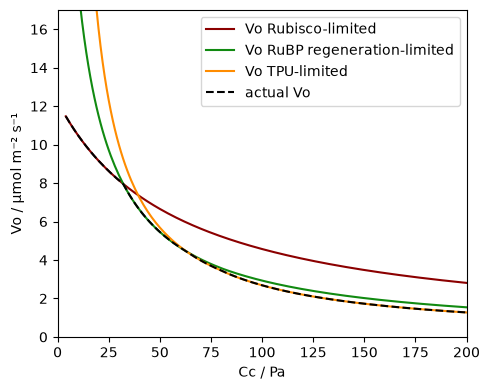

In [10]:
fig, axs = plt.subplots(nrows=1, ncols=1, figsize=(5, 4), squeeze=False)
ax0 = axs[0, 0]
ax0.plot(tables["vo"]["x"], tables["vo"]["Vo_c"], color="#8b0000", label="Vo Rubisco-limited")
ax0.plot(tables["vo"]["x"], tables["vo"]["Vo_j"], color="#118a11", label="Vo RuBP regeneration-limited")
ax0.plot(tables["vo"]["x"], tables["vo"]["Vo_p"], color="#ff8c00", label="Vo TPU-limited")
ax0.plot(tables["vo"]["x"], tables["vo"]["Vo"], color="black", ls="--", label="actual Vo")
ax0.set_xlabel("Cc / Pa")
ax0.set_ylabel("Vo / µmol m⁻² s⁻¹")
ax0.set_xlim(0, 200)
ax0.set_ylim(0, 17)
ax0.legend()
plt.tight_layout()
plt.show()